<a href="https://colab.research.google.com/github/allusaatvikacs24-collab/BIS_LAB/blob/main/Ant_Colony.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install numpy matplotlib

Best route: 2 -> 4 -> 6 -> 3 -> 5 -> 1 -> 7 -> 0 -> 2
Shortest distance: 29.406


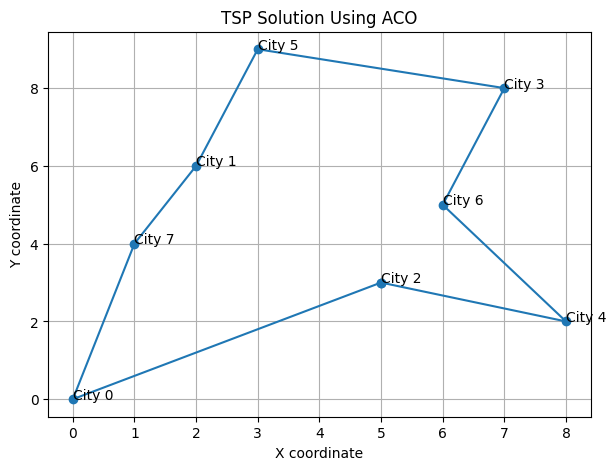

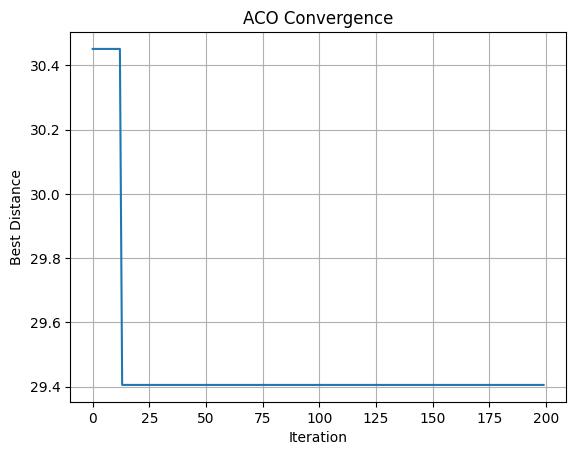

In [2]:

import numpy as np
import matplotlib.pyplot as plt

# 1. Define cities using coordinates
cities = np.array([
    [0, 0], [2, 6], [5, 3], [7, 8],
    [8, 2], [3, 9], [6, 5], [1, 4]
])

n = len(cities)

# Calculate distances between cities
dist = np.linalg.norm(
    cities[:, None, :] - cities[None, :, :],
    axis=2
)

# Heuristic information: shorter distance is preferred
heuristic = 1 / (dist + 1e-10)
np.fill_diagonal(heuristic, 0)

# 2. Initialize ACO parameters
ants = n
iterations = 200
alpha = 1.0
beta = 5.0
rho = 0.5
Q = 100

pheromone = np.ones((n, n))
np.fill_diagonal(pheromone, 0)

rng = np.random.default_rng(42)

best_route = None
best_distance = float("inf")
history = []

# 3. Construct a route for each ant
def construct_route():
    start = int(rng.integers(n))
    route = [start]
    unvisited = set(range(n))
    unvisited.remove(start)

    while unvisited:
        current = route[-1]
        candidates = np.array(sorted(unvisited))

        weights = (
            pheromone[current, candidates] ** alpha
            * heuristic[current, candidates] ** beta
        )

        probabilities = weights / weights.sum()
        next_city = int(
            rng.choice(candidates, p=probabilities)
        )

        route.append(next_city)
        unvisited.remove(next_city)

    return route

# 4. Calculate total distance, including return to start
def route_length(route):
    total = sum(
        dist[route[i], route[i + 1]]
        for i in range(n - 1)
    )
    total += dist[route[-1], route[0]]
    return total

# 5. Run ACO iterations
for iteration in range(iterations):
    routes = []
    lengths = []

    for _ in range(ants):
        route = construct_route()
        length = route_length(route)

        routes.append(route)
        lengths.append(length)

        if length < best_distance:
            best_distance = length
            best_route = route.copy()

    # Pheromone evaporation
    pheromone *= (1 - rho)

    # Deposit pheromone on each ant's route
    for route, length in zip(routes, lengths):
        deposit = Q / length

        for i in range(n):
            a = route[i]
            b = route[(i + 1) % n]

            pheromone[a, b] += deposit
            pheromone[b, a] += deposit

    history.append(best_distance)

# 6. Display best solution
closed_route = best_route + [best_route[0]]

print("Best route:", " -> ".join(map(str, closed_route)))
print(f"Shortest distance: {best_distance:.3f}")

# 7. Plot best route
route_points = cities[closed_route]

plt.figure(figsize=(7, 5))
plt.plot(route_points[:, 0], route_points[:, 1], "o-")

for i, (x, y) in enumerate(cities):
    plt.annotate(f"City {i}", (x, y))

plt.title("TSP Solution Using ACO")
plt.xlabel("X coordinate")
plt.ylabel("Y coordinate")
plt.grid(True)
plt.show()

# Plot convergence
plt.plot(history)
plt.title("ACO Convergence")
plt.xlabel("Iteration")
plt.ylabel("Best Distance")
plt.grid(True)
plt.show()
#https://ieeexplore.ieee.org/document/4659446